<a href="https://colab.research.google.com/github/mrayhanz/PCVK-Ganjil-2026/blob/main/week7_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

Kelas : TI - 3G

Nim : 244107020027

Absen : 19

In [ ]:
NAMA = 'Muhammad Rayhan Zamzami'
NIM = '244107020027' # ganti dengan NIM sendiri
print(NAMA, NIM)

Muhammad Rayhan Zamzami 244107020027


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# TUGAS D1

In [ ]:
# Import Library
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, segmentation
from sklearn.cluster import KMeans
BASE = '/content/drive/MyDrive/PCVK-2026/Images'

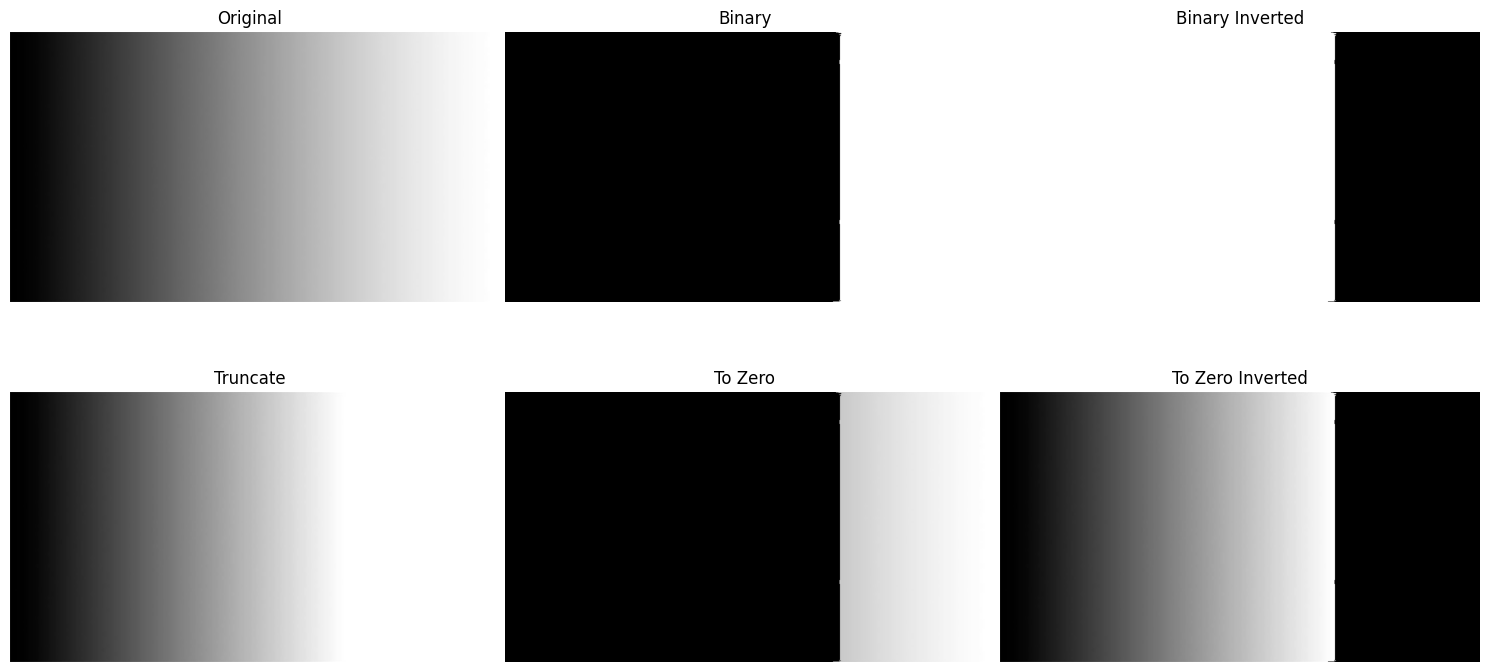

In [ ]:
# Baca gambar
filename = f'{BASE}/gradient.jpg'

img = cv.imread(filename)

if img is None:
    raise FileNotFoundError(f'File tidak ditemukan: {filename}')

# Ubah ke grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Threshold
T = 200
MAX = 255

# =================================
# MANUAL GLOBAL THRESHOLD
# =================================

# 1. BINARY
binary = np.where(gray > T, MAX, 0).astype(np.uint8)

# 2. BINARY INVERTED
binary_inv = np.where(gray > T, 0, MAX).astype(np.uint8)

# 3. TRUNCATE
trunc = np.where(gray > T, T, gray).astype(np.uint8)

# 4. TO ZERO
tozero = np.where(gray > T, gray, 0).astype(np.uint8)

# 5. TO ZERO INVERTED
tozero_inv = np.where(gray > T, 0, gray).astype(np.uint8)


# =================================
# TAMPILKAN HASIL
# =================================

titles = [
    'Original',
    'Binary',
    'Binary Inverted',
    'Truncate',
    'To Zero',
    'To Zero Inverted'
]

images = [
    gray,
    binary,
    binary_inv,
    trunc,
    tozero,
    tozero_inv
]

plt.figure(figsize=(15, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

### Analisis

Binary Inverted merupakan kebalikan dari Binary.
Truncate mempertahankan piksel yang nilainya ≤ 200, sedangkan piksel di atas 200 dipotong menjadi 200.
To Zero mempertahankan piksel di atas 200 dan mengubah piksel ≤ 200 menjadi 0.
To Zero Inverted melakukan kebalikan dari To Zero. Ini sesuai aturan lima global threshold pada modul.

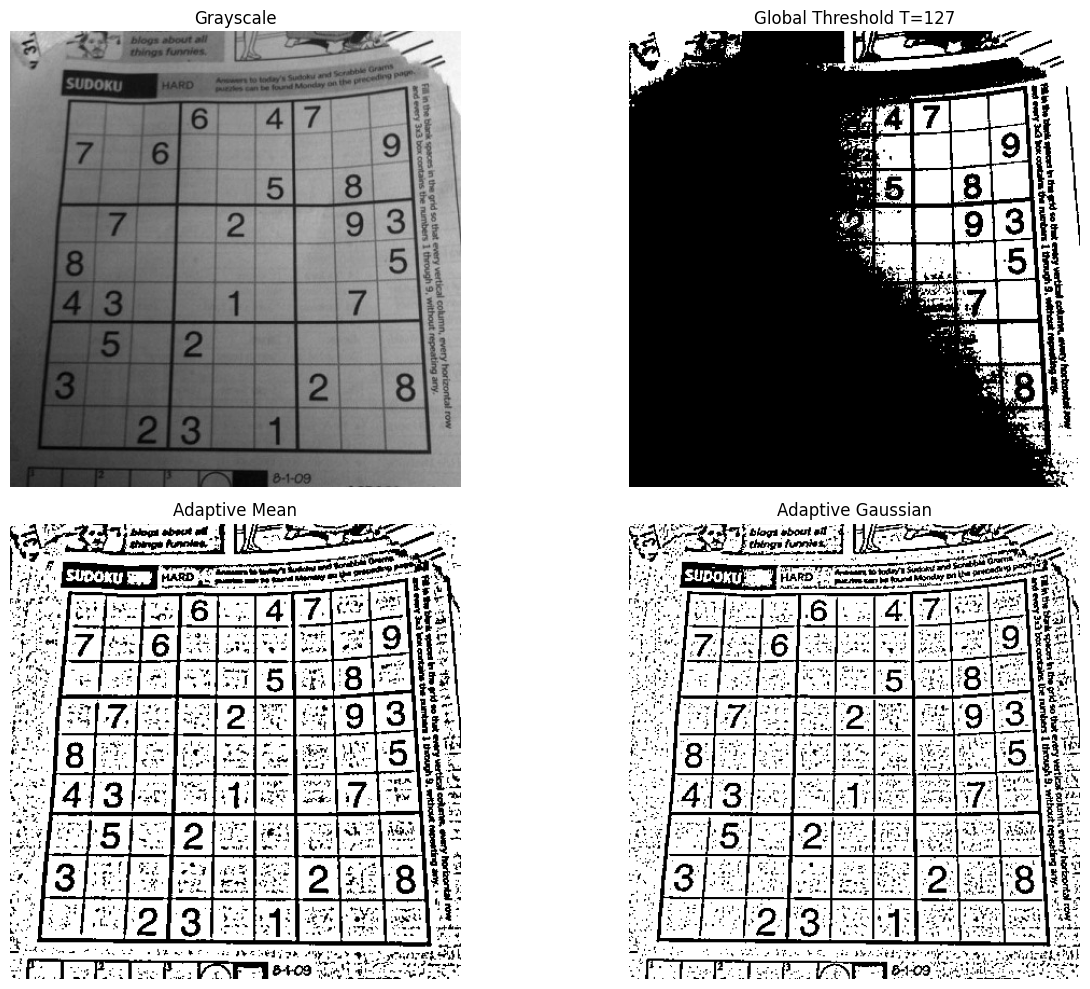

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view

# Baca gambar Sudoku
filename = f'{BASE}/sudoku-original.jpg'

img = cv.imread(filename)

if img is None:
    raise FileNotFoundError(f'File tidak ditemukan: {filename}')

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Parameter
block_size = 11
C = 2
sigma = 2


# ==========================================
# GLOBAL THRESHOLD MANUAL
# ==========================================

global_threshold = np.where(
    gray > 127, 255,0).astype(np.uint8)

# ==========================================
# GAUSSIAN KERNEL MANUAL
# ==========================================

def gaussian_kernel(size, sigma):

    radius = size // 2
    x = np.arange(-radius,radius + 1)
    xx, yy = np.meshgrid(x, x)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / kernel.sum()
    return kernel
# ==========================================
# ADAPTIVE MEAN MANUAL
# ==========================================

def adaptive_mean_manual(
    gray,block_size=11,C=2):
    pad = block_size // 2
    padded = np.pad(gray.astype(np.float64),pad,mode='reflect')
    windows = sliding_window_view(padded,(block_size, block_size))
    local_mean = windows.mean(axis=(-2, -1))
    result = np.where(gray > local_mean - C,255,0)
    return result.astype(np.uint8)
# ==========================================
# ADAPTIVE GAUSSIAN MANUAL
# ==========================================

def adaptive_gaussian_manual(gray,block_size=11,C=2,sigma=2):

    pad = block_size // 2
    padded = np.pad(gray.astype(np.float64),pad,mode='reflect')
    windows = sliding_window_view(padded,(block_size, block_size))
    kernel = gaussian_kernel(block_size,sigma)
    local_gaussian = np.sum(windows * kernel,axis=(-2, -1))
    result = np.where(gray > local_gaussian - C,255,0)
    return result.astype(np.uint8)

# Jalankan
adaptive_mean = adaptive_mean_manual(gray,block_size=11,C=2)
adaptive_gaussian = adaptive_gaussian_manual(gray,block_size=11,C=2,sigma=2)

# ==========================================
# TAMPILKAN HASIL
# ==========================================

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(global_threshold, cmap='gray')
plt.title('Global Threshold T=127')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(adaptive_mean, cmap='gray')
plt.title('Adaptive Mean')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(adaptive_gaussian, cmap='gray')
plt.title('Adaptive Gaussian')
plt.axis('off')

plt.tight_layout()
plt.show()

### Analisis
Global threshold menggunakan satu nilai threshold untuk seluruh citra. Karena Sudoku mempunyai pencahayaan yang tidak merata, hasilnya dapat kurang baik.

Adaptive Mean menghitung rata-rata intensitas pada area lokal, sedangkan Adaptive Gaussian menggunakan bobot Gaussian sehingga piksel yang lebih dekat dengan pusat window memiliki pengaruh lebih besar.

In [ ]:
# ==========================================
# OTSU MANUAL
# ==========================================

def otsu_manual(gray):

    # Histogram
    histogram = np.bincount(gray.ravel(),minlength=256).astype(np.float64)
    total_pixels = gray.size

    # Probabilitas setiap intensitas
    probability = histogram / total_pixels
    intensity = np.arange(256,dtype=np.float64)

    # Probabilitas kumulatif
    omega = np.cumsum(probability)

    # Mean kumulatif
    mu = np.cumsum(probability * intensity)

    # Mean total
    mu_total = mu[-1]

    # Between-class variance
    variance = np.zeros(256)
    valid = ((omega > 0) &(omega < 1))
    variance[valid] = ((mu_total * omega[valid] - mu[valid]) ** 2 / (omega[valid] * (1 - omega[valid])))

    # Threshold terbaik
    threshold = int(np.argmax(variance))

    # Binarisasi
    result = np.where( gray > threshold,255,0).astype(np.uint8)

    return result, threshold

Threshold Global = 127
Threshold Otsu Manual = 112


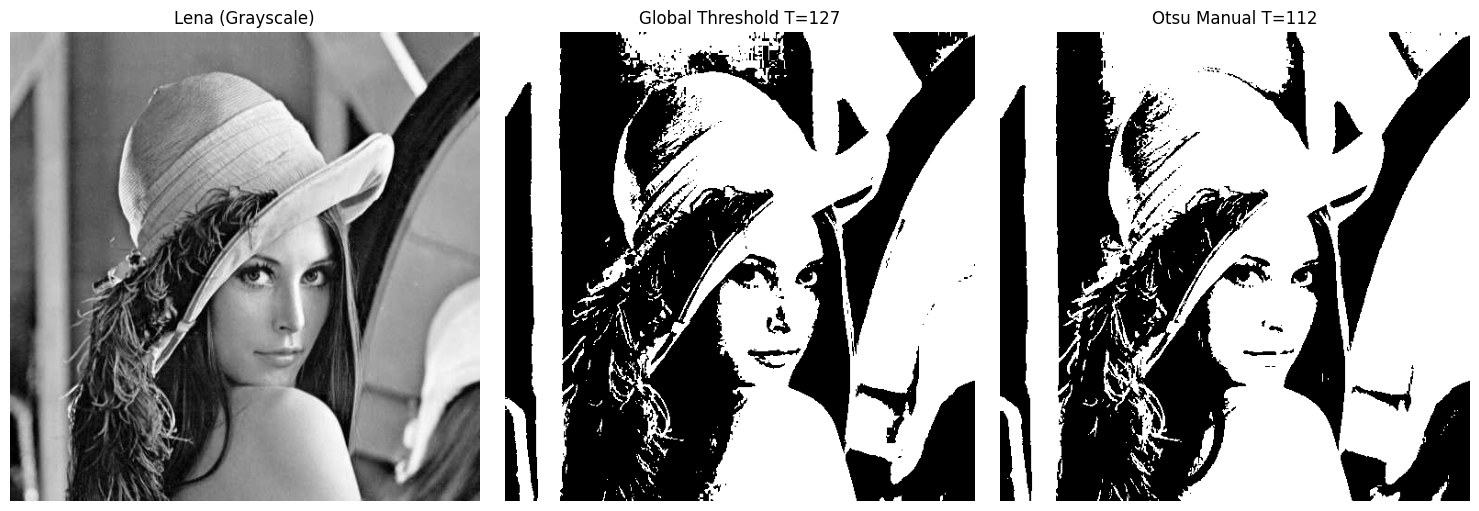

In [ ]:
# Baca Lena
filename = f'{BASE}/lena.jpg'
lena_color = cv.imread(filename)
if lena_color is None:
    raise FileNotFoundError(f'File tidak ditemukan: {filename}')

# Ubah ke grayscale
lena = cv.cvtColor(lena_color, cv.COLOR_BGR2GRAY)

# Otsu manual
otsu_result, otsu_threshold = otsu_manual(lena)

# Global threshold
global_threshold = 127
global_result = np.where(lena > global_threshold, 255, 0).astype(np.uint8)

# Tampilkan nilai
print('Threshold Global =', global_threshold)
print('Threshold Otsu Manual =', otsu_threshold)

# Tampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(lena, cmap='gray')
plt.title('Lena (Grayscale)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_result, cmap='gray')
plt.title(f'Global Threshold T={global_threshold}')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(otsu_result, cmap='gray')
plt.title(f'Otsu Manual T={otsu_threshold}')
plt.axis('off')

plt.tight_layout()
plt.show()

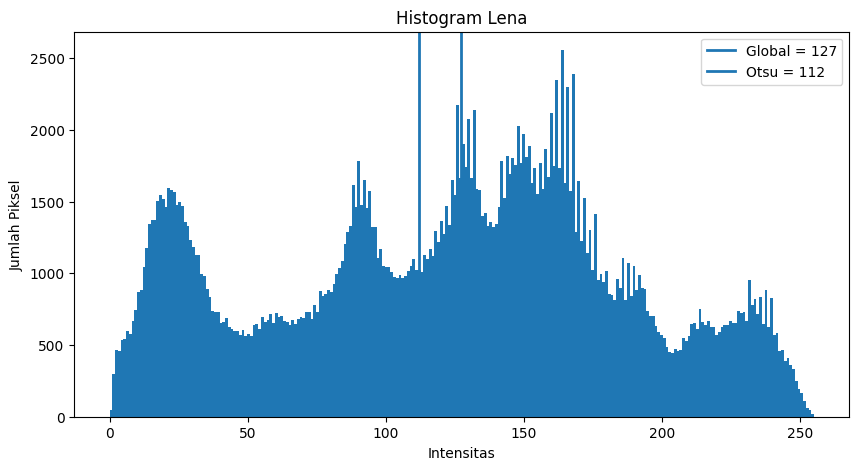

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    lena.ravel(),
    bins=256,
    range=(0, 255)
)

plt.axvline(
    global_threshold,
    linewidth=2,
    label=f'Global = {global_threshold}'
)

plt.axvline(
    otsu_threshold,
    linewidth=2,
    label=f'Otsu = {otsu_threshold}'
)

plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.title('Histogram Lena')
plt.legend()

plt.show()

### Pertanyaan: Kenapa Binary Thresholding Lena bisa hitam semua?
Karena threshold yang digunakan terlalu tinggi dibandingkan nilai intensitas piksel pada citra. Jika seluruh piksel memiliki nilai ≤ threshold, maka aturan Binary:

piksel > threshold → 255

piksel ≤ threshold → 0

tidak akan menghasilkan piksel putih sama sekali.
Pada contoh di modul, Lena low contrast mempunyai rentang intensitas rendah dan threshold sekitar 92 dapat digunakan agar objek tetap terlihat.

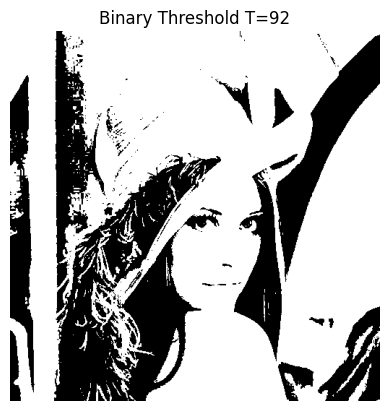

In [ ]:
T = 92

lena_92 = np.where(
    lena > T,
    255,
    0
).astype(np.uint8)

plt.imshow(
    lena_92,
    cmap='gray'
)

plt.title('Binary Threshold T=92')
plt.axis('off')
plt.show()

Threshold Global = 127
Threshold Otsu = 150


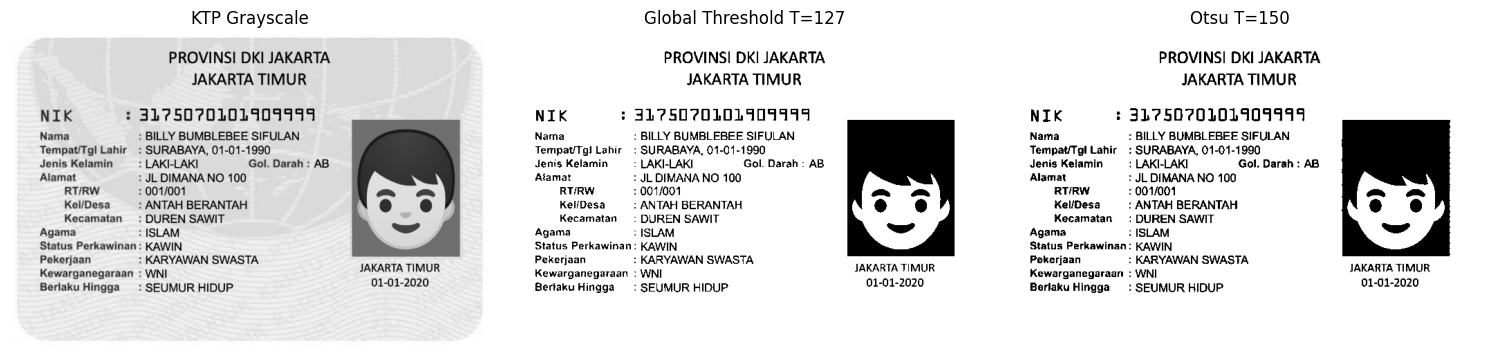

In [ ]:
# ==========================================
# OTSU PADA KTP
# ==========================================

ktp_path = f'{BASE}/ktp_fulan.jpg'

ktp = cv.imread(ktp_path,cv.IMREAD_GRAYSCALE)

if ktp is None:
    print('File ktp_fulan.jpg belum ditemukan.')
else:

    # Otsu
    ktp_otsu, ktp_threshold = otsu_manual(ktp)

    # Global threshold 127
    ktp_global = np.where(ktp > 127,255,0).astype(np.uint8)
    print('Threshold Global = 127')
    print('Threshold Otsu =',ktp_threshold)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(ktp, cmap='gray')
    plt.title('KTP Grayscale')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(ktp_global, cmap='gray')
    plt.title('Global Threshold T=127')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(ktp_otsu, cmap='gray')
    plt.title(
        f'Otsu T={ktp_threshold}'
    )
    plt.axis('off')

    plt.tight_layout()
    plt.show()

*** Seed (baris, kolom): (36, 43) | intensitas: 159.0


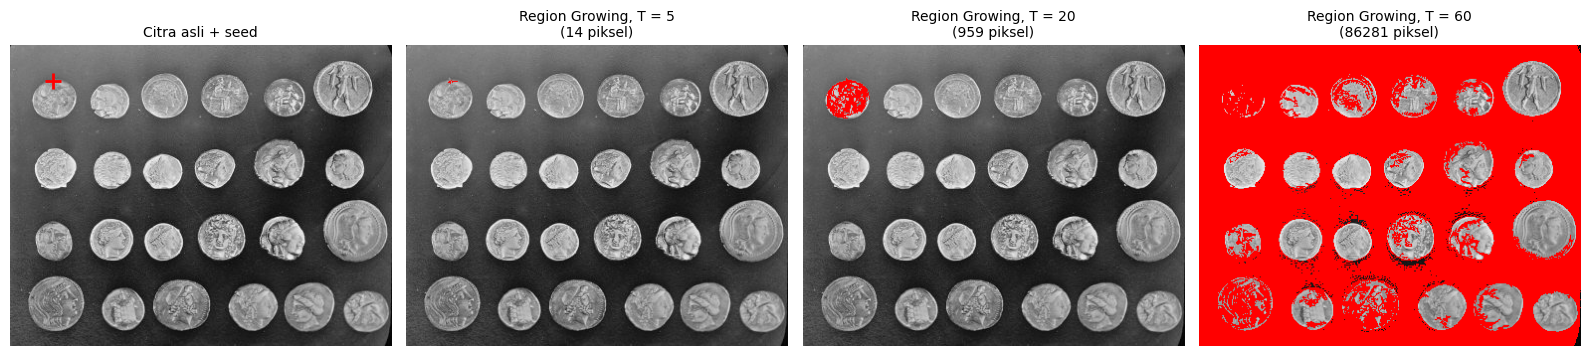

In [ ]:
# Load citra
img = data.coins()

# Fungsi Region Growing dengan pembaruan Rata-rata (Mean)
def region_growing(image, seed, T):
    segmented = np.zeros_like(image, dtype=bool)
    rows, cols = image.shape

    queue = [seed]
    segmented[seed] = True

    # Simpan total intensitas dan jumlah piksel untuk menghitung rata-rata
    region_sum = float(image[seed])
    region_count = 1

    # 8-connected neighborhood
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1),
                  (-1, -1), (-1, 1), (1, -1), (1, 1)]

    while queue:
        current_r, current_c = queue.pop(0)

        # Hitung rata-rata intensitas region saat ini
        region_mean = region_sum / region_count

        for dr, dc in directions:
            r, c = current_r + dr, current_c + dc
            if 0 <= r < rows and 0 <= c < cols:
                if not segmented[r, c]:
                    # Bandingkan dengan rata-rata region, bukan seed awal
                    if abs(float(image[r, c]) - region_mean) <= T:
                        segmented[r, c] = True
                        queue.append((r, c))

                        # Update total dan jumlah piksel region
                        region_sum += image[r, c]
                        region_count += 1

    return segmented

# --- FOKUS PADA 1 SEED SESUAI CONTOH ---
seed = (36, 43)
T_values = [5, 20, 60]
intensitas = img[seed]

print(f"*** Seed (baris, kolom): {seed} | intensitas: {float(intensitas)}")

# Buat grid 1x4 (1 baris, 4 kolom)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# 1. Citra asli + seed
axes[0].imshow(img, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
axes[0].set_title('Citra asli + seed', fontsize=10)
axes[0].axis('off')

# 2. Plot hasil Region Growing untuk T=5, 20, 60
for i, T in enumerate(T_values):
    mask = region_growing(img, seed, T)
    jml_piksel = np.sum(mask)

    img_rgb = np.stack((img,) * 3, axis=-1).astype(float) / 255.0
    img_rgb[mask] = [1.0, 0.0, 0.0] # Warna merah

    axes[i+1].imshow(img_rgb)
    axes[i+1].set_title(f'Region Growing, T = {T}\n({jml_piksel} piksel)', fontsize=10)
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

*** Seed (baris, kolom): (36, 43) | Intensitas: 159.000000
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


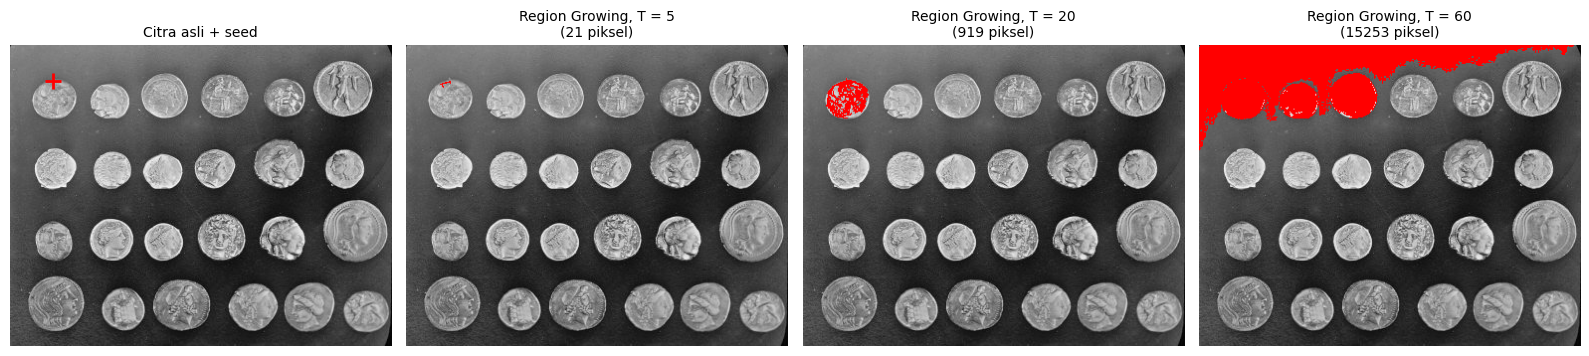

In [ ]:
from skimage import data
from skimage.segmentation import flood

# 1. Load citra
img = data.coins()
seed = (36, 43)
tolerances = [5, 20, 60]

# Berdasarkan gambar contoh, intensitas ditampilkan sebagai 159.000000
intensitas_teks = 159.000000

# 2. Jalankan segmentasi flood dan cetak teks output
print(f"*** Seed (baris, kolom): {seed} | Intensitas: {intensitas_teks:.6f}")

masks = []
pixel_counts = []

for T in tolerances:
    # Gunakan fungsi siap pakai flood() dengan connectivity=1 (4 tetangga)
    mask = flood(img, seed_point=seed, tolerance=T, connectivity=1)

    jml_piksel = np.sum(mask)
    masks.append(mask)
    pixel_counts.append(jml_piksel)

    # Cetak jumlah piksel per toleransi sesuai gambar contoh
    print(f"Toleransi {T}: {jml_piksel} piksel")

# 3. Buat visualisasi grid 1x4
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# URUTAN 1: Citra asli + seed
axes[0].imshow(img, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
axes[0].set_title('Citra asli + seed', fontsize=10)
axes[0].axis('off')

# URUTAN 2, 3, 4: Hasil flood untuk T=5, 20, 60
for i, T in enumerate(tolerances):
    mask = masks[i]
    count = pixel_counts[i]

    # Konversi ke RGB untuk area tersegmentasi (warna merah)
    img_rgb = np.stack((img,) * 3, axis=-1).astype(float) / 255.0
    img_rgb[mask] = [1.0, 0.0, 0.0]

    axes[i+1].imshow(img_rgb)
    axes[i+1].set_title(f'Region Growing, T = {T}\n({count} piksel)', fontsize=10)
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

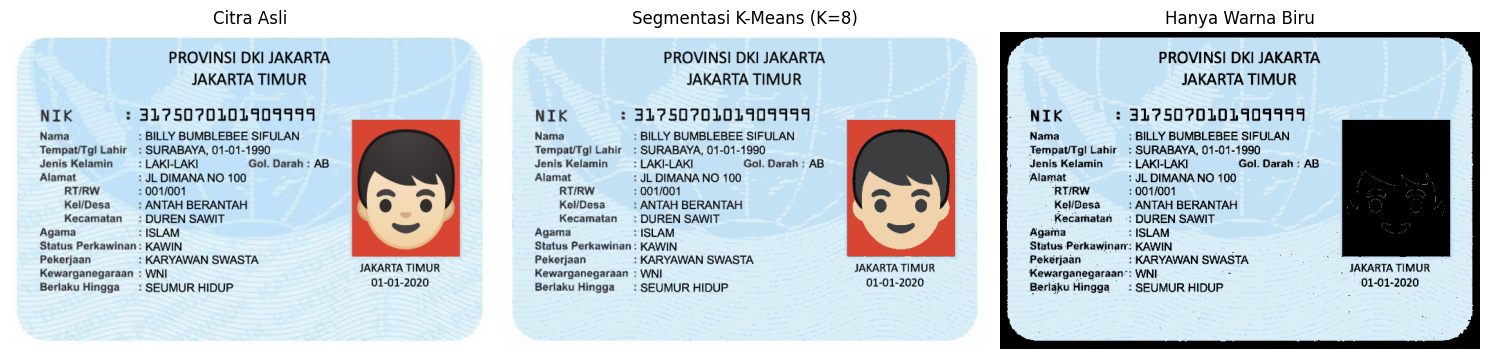

In [ ]:
from sklearn.cluster import KMeans

ktp_path = f'{BASE}/ktp_fulan.jpg'
img_bgr = cv.imread(ktp_path)

if img_bgr is None:
    raise FileNotFoundError(f'File tidak ditemukan: {ktp_path}')

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# Ubah bentuk citra menjadi array 2D (jumlah piksel x 3 channel warna)
pixels = img_rgb.reshape((-1, 3))

# Jalankan K-Means
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans.fit(pixels)

# Rekonstruksi citra dari hasil K-Means (ganti nilai piksel dengan nilai centroid clusternya)
segmented_pixels = kmeans.cluster_centers_[kmeans.labels_]
segmented_img = segmented_pixels.reshape(img_rgb.shape).astype(np.uint8)

# Konversi citra K-Means ke HSV
hsv_img = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = cv.split(hsv_img)

# Buat mask kosong
mask_biru = np.zeros_like(H, dtype=bool)

# (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
mask_biru[kelompok_biru] = True

# Terapkan mask untuk memunculkan hanya warna biru, sisanya menjadi hitam (0)
hanya_biru = np.zeros_like(segmented_img)
hanya_biru[mask_biru] = segmented_img[mask_biru]

# 4. Visualisasi hasil persis seperti format di gambar
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Citra Asli
axes[0].imshow(img_rgb)
axes[0].set_title('Citra Asli', fontsize=12)
axes[0].axis('off')

# Plot 2: Segmentasi K-Means (K=8)
axes[1].imshow(segmented_img)
axes[1].set_title('Segmentasi K-Means (K=8)', fontsize=12)
axes[1].axis('off')

# Plot 3: Hanya Warna Biru
axes[2].imshow(hanya_biru)
axes[2].set_title('Hanya Warna Biru', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

# D2 KELOMPOK

## Identitas Kelompok:
1. **Mohammad Al Hafis Hidayatulloh** (NIM: `254107023005`)
2. **Radit Firansah** (NIM: `244107020196`)
3. **Muhammad Rayhan Zamzami** (NIM: `244107020027`)
4. **Nurfinka Lailasari** (NIM: `244107020211`)

In [ ]:
# Instalasi Tesseract OCR dan paket bahasa Indonesia di lingkungan Colab
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract tabulate

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
# Import Library OCR dan Definisi Data Anggota Kelompok
import pytesseract
import pandas as pd
from tabulate import tabulate

CONFIG_OCR = '--psm 3'
LANG_OCR = 'ind'
CONF_MIN = 60
LEBAR_STANDAR = 1000
BLOCK_ADAPTIVE = 31
C_ADAPTIVE = 10

# 10 kata/angka acuan faktual yang tertera pada kartu KTM masing-masing anggota
DATA_KTM_ANGGOTA = {
    'rayhan': {
        'nama_lengkap': 'Muhammad Rayhan Zamzami',
        'nim': '244107020027',
        'file_ktm': 'ktm_rayhan',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'MUHAMMAD', 'RAYHAN', 'ZAMZAMI', '244107020027', 'TEKNIK', 'INFORMATIKA']
    },
    'hafis': {
        'nama_lengkap': 'Mohammad Al Hafis Hidayatulloh',
        'nim': '254107023005',
        'file_ktm': 'ktm_hafis',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'MOHAMMAD', 'HAFIS', 'HIDAYATULLOH', '254107023005', 'TEKNIK', 'INFORMATIKA']
    },
    'radit': {
        'nama_lengkap': 'Radit Firansah',
        'nim': '244107020196',
        'file_ktm': 'ktm_radit',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'RADIT', 'FIRANSAH', '244107020196', 'D-IV', 'TEKNIK', 'INFORMATIKA']
    },
    'nurfinka': {
        'nama_lengkap': 'Nurfinka Lailasari',
        'nim': '244107020211',
        'file_ktm': 'ktm_nurfinka',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'NURFINKA', 'LAILASARI', '244107020211', 'D-IV', 'TEKNIK', 'INFORMATIKA']
    }
}

print("Konfigurasi OCR:")
print(f"  - Bahasa      : {LANG_OCR}")
print(f"  - PSM config  : {CONFIG_OCR}")
print(f"  - Lebar citra : {LEBAR_STANDAR} px")
print(f"  - Min Conf    : {CONF_MIN}%")

Konfigurasi OCR:
  - Bahasa      : ind
  - PSM config  : --psm 3
  - Lebar citra : 1000 px
  - Min Conf    : 60%


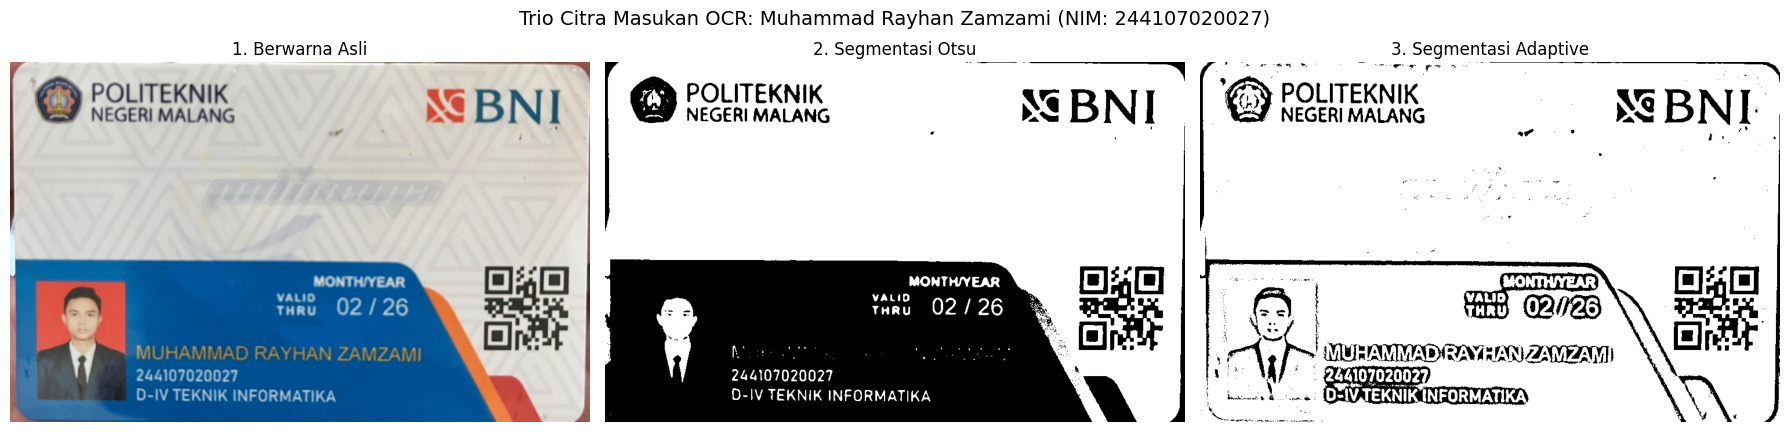

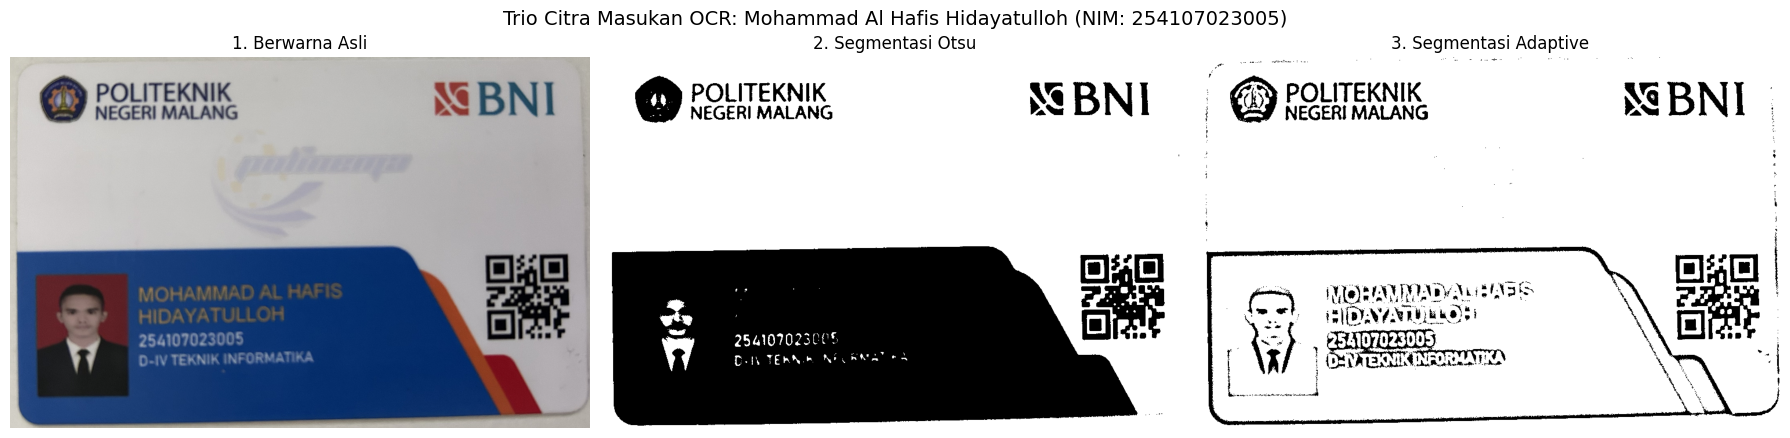

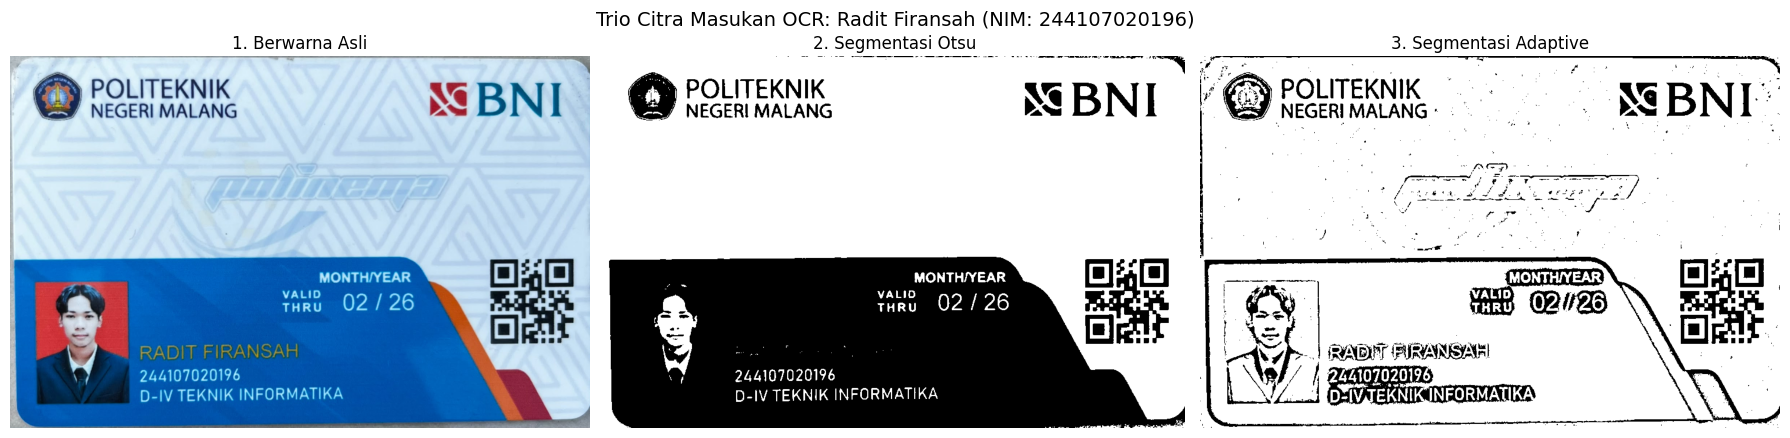

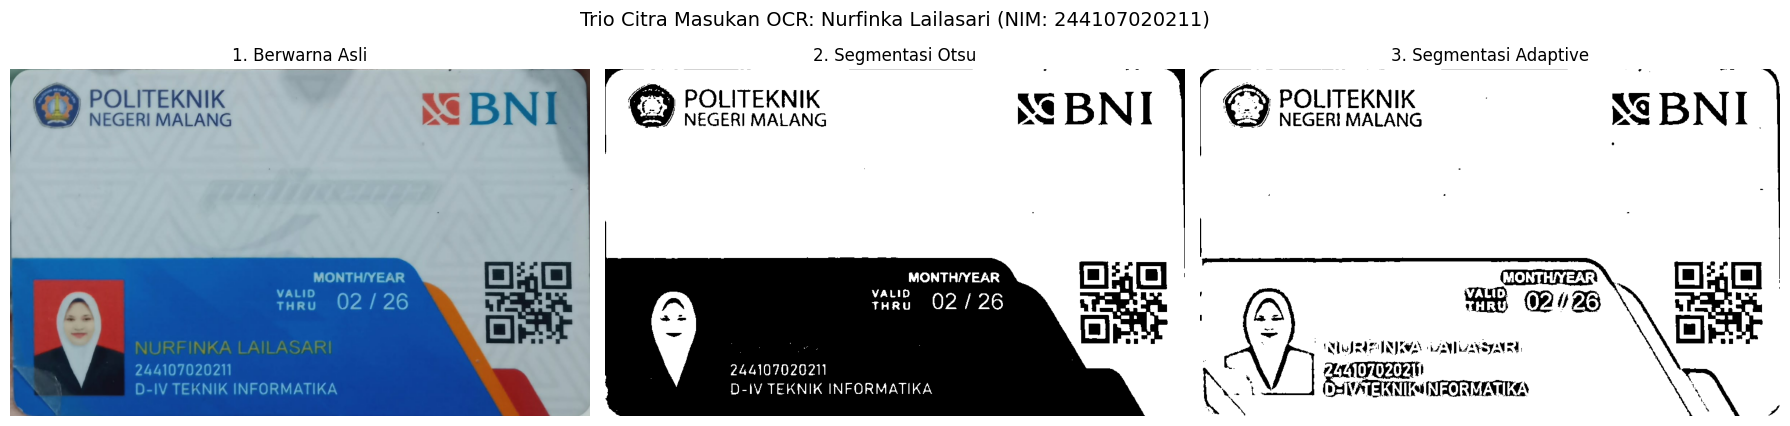

In [ ]:
import os

def siapkan_trio_citra(awalan_file):
    """Membaca KTM, menyeragamkan ukuran ke lebar 1000 px, dan menghasilkan 3 citra uji."""
    # Mencoba mencari file dengan ekstensi .jpg atau .png di direktori BASE
    path_gambar = f'{BASE}/{awalan_file}.jpg'
    if not os.path.exists(path_gambar):
        path_gambar = f'{BASE}/{awalan_file}.png'

    bgr = cv.imread(path_gambar)
    if bgr is None:
        raise FileNotFoundError(f'File tidak ditemukan: {BASE}/{awalan_file} (.jpg atau .png)')

    h, w = bgr.shape[:2]
    # Resize menjaga aspect ratio
    bgr_resized = cv.resize(bgr, (LEBAR_STANDAR, int(h * LEBAR_STANDAR / w)))
    gray = cv.cvtColor(bgr_resized, cv.COLOR_BGR2GRAY)

    # 1. Otsu Thresholding
    _, otsu_thresh = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # 2. Adaptive Gaussian Thresholding
    adaptive_thresh = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                           cv.THRESH_BINARY, BLOCK_ADAPTIVE, C_ADAPTIVE)

    return {
        'BERWARNA': cv.cvtColor(bgr_resized, cv.COLOR_BGR2RGB),
        'OTSU': otsu_thresh,
        'ADAPTIVE': adaptive_thresh
    }

# Siapkan trio citra untuk seluruh 4 anggota kelompok
citra_kelompok = {}
for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    try:
        citra_kelompok[id_anggota] = siapkan_trio_citra(data_ag['file_ktm'])
    except FileNotFoundError as e:
        print(e)

# Tampilkan visualisasi 3 citra untuk masing-masing anggota
for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    if id_anggota in citra_kelompok:
        trio = citra_kelompok[id_anggota]

        fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
        fig.suptitle(f"Trio Citra Masukan OCR: {data_ag['nama_lengkap']} (NIM: {data_ag['nim']})", fontsize=14)

        titles = ['1. Berwarna Asli', '2. Segmentasi Otsu', '3. Segmentasi Adaptive']
        images = [trio['BERWARNA'], trio['OTSU'], trio['ADAPTIVE']]

        for i in range(3):
            if len(images[i].shape) == 2:
                axes[i].imshow(images[i], cmap='gray')
            else:
                axes[i].imshow(images[i])
            axes[i].set_title(titles[i])
            axes[i].axis('off')

        plt.tight_layout()
        plt.show()

In [ ]:
# Eksekusi OCR image_to_string
teks_ocr = {}

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    teks_ocr[id_anggota] = {}
    print("=" * 70)
    print(f"HASIL OCR TEKS LENGKAP: {data_ag['nama_lengkap'].upper()} ({data_ag['nim']})")
    print("=" * 70)

    for jenis_citra in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
        citra_input = citra_kelompok[id_anggota][jenis_citra]
        # Jika citra biner (grayscale 2D), Tesseract langsung memprosesnya
        raw_text = pytesseract.image_to_string(citra_input, lang=LANG_OCR, config=CONFIG_OCR)
        teks_ocr[id_anggota][jenis_citra] = raw_text.strip()

        print(f"--- [{jenis_citra}] ---")
        teks_tampil = raw_text.strip() if raw_text.strip() else "(TIDAK ADA TEKS TERDETEKSI)"
        print(teks_tampil)
        print()

HASIL OCR TEKS LENGKAP: MUHAMMAD RAYHAN ZAMZAMI (244107020027)
--- [BERWARNA] ---
| POLITEKNIK
NEGERI MALANG

MONTH/YEAR

turu 02/26

MUHAMMAD RAYHAN ZAMZAMI
244107020027
D-IV TEKNIK INFORMATIKA

--- [OTSU] ---
POLITEKNIK
NEGERI MALANG

@
w
Z
emang

Turu 02/26 '
244107020027

D-IV TEKNIK INFORMATIKA

--- [ADAPTIVE] ---
KO Ae ANK, Dea X BNI:

HASIL OCR TEKS LENGKAP: MOHAMMAD AL HAFIS HIDAYATULLOH (254107023005)
--- [BERWARNA] ---
POT BNI
MOHAMMAD /

HIDAY

254107023005
D-IV TEKNIK INFORMATIKA

--- [OTSU] ---
MERE MALANG Ae BNI

st

Sa 254107023005
DAN TEKAN NEKAT IA

--- [ADAPTIVE] ---
OA S$BNI

MOHAMMALAGE AFIS
Pua YATULLOHI

HASIL OCR TEKS LENGKAP: RADIT FIRANSAH (244107020196)
--- [BERWARNA] ---
y POLITEKNIK —
| AM PAN Ea NG BN I

--- [OTSU] ---
3 POLITEKNIK
8) NEGERI MALANG NC BNI

MONTH/YEAR

Haku 02/26

244107020196
D-IV TEKNIK INFORMATIKA

--- [ADAPTIVE] ---
Ty POLI uan | 3
G9 PELTEKNIK Da, xg BNI

RAD AANGAN

244107020126
#EDTIVTEKNIK INEORMATIKAY

HASIL OCR TEKS LENGKAP: NURFIN

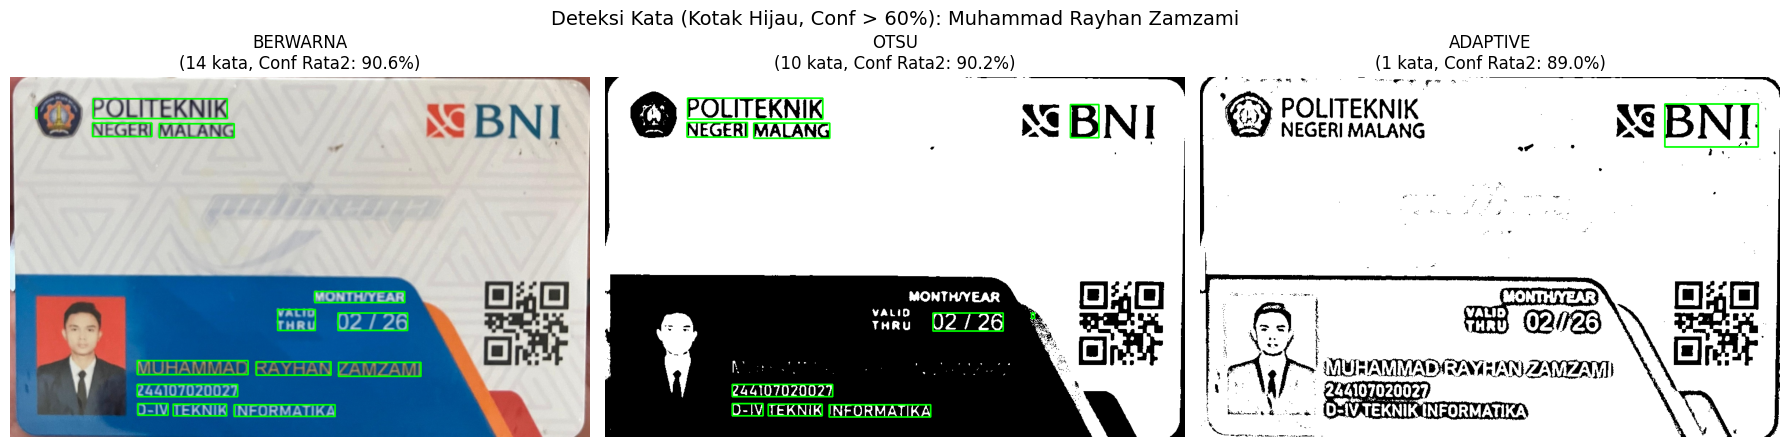

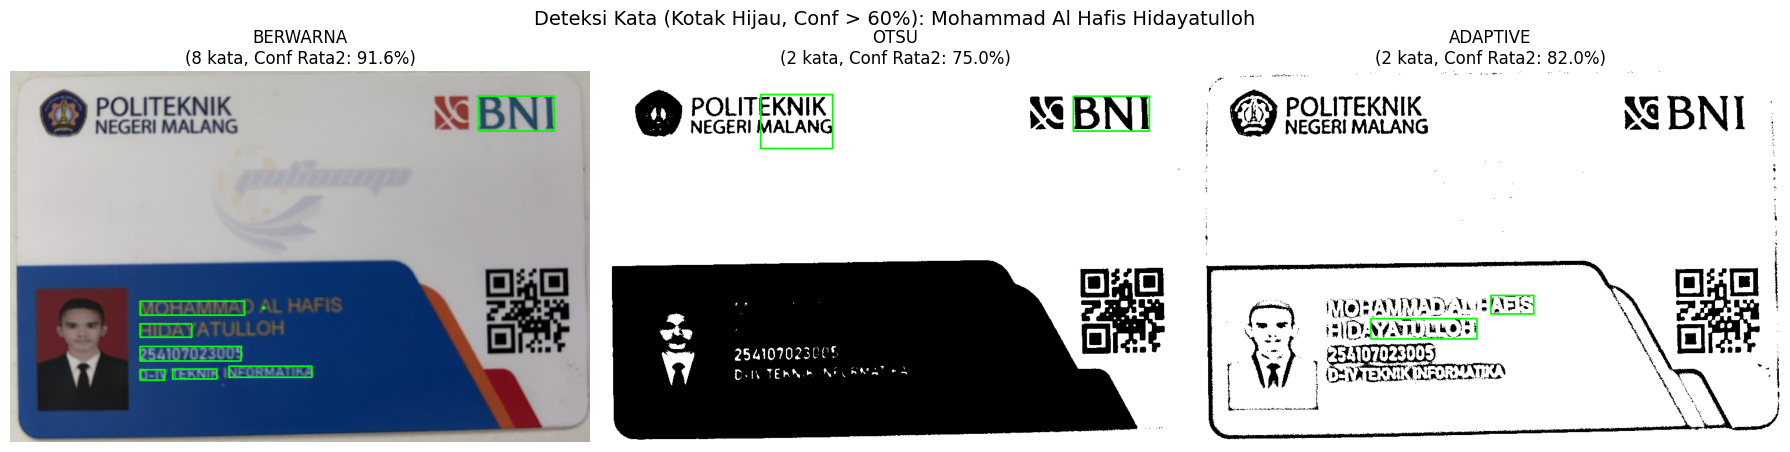

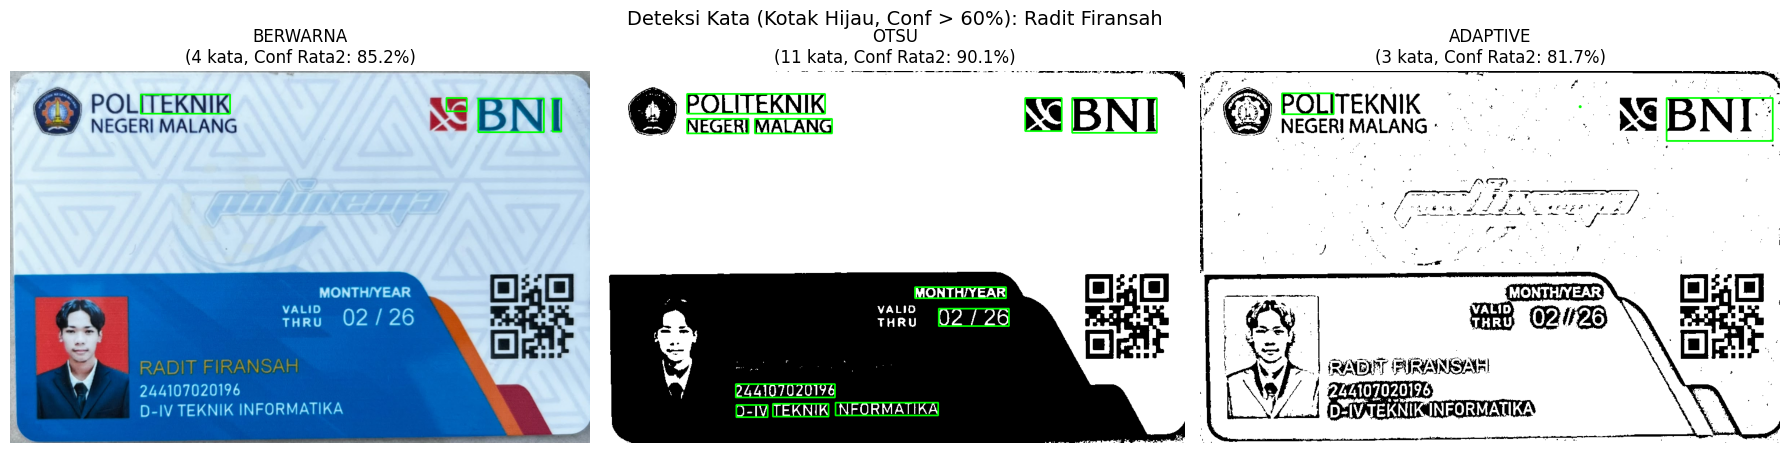

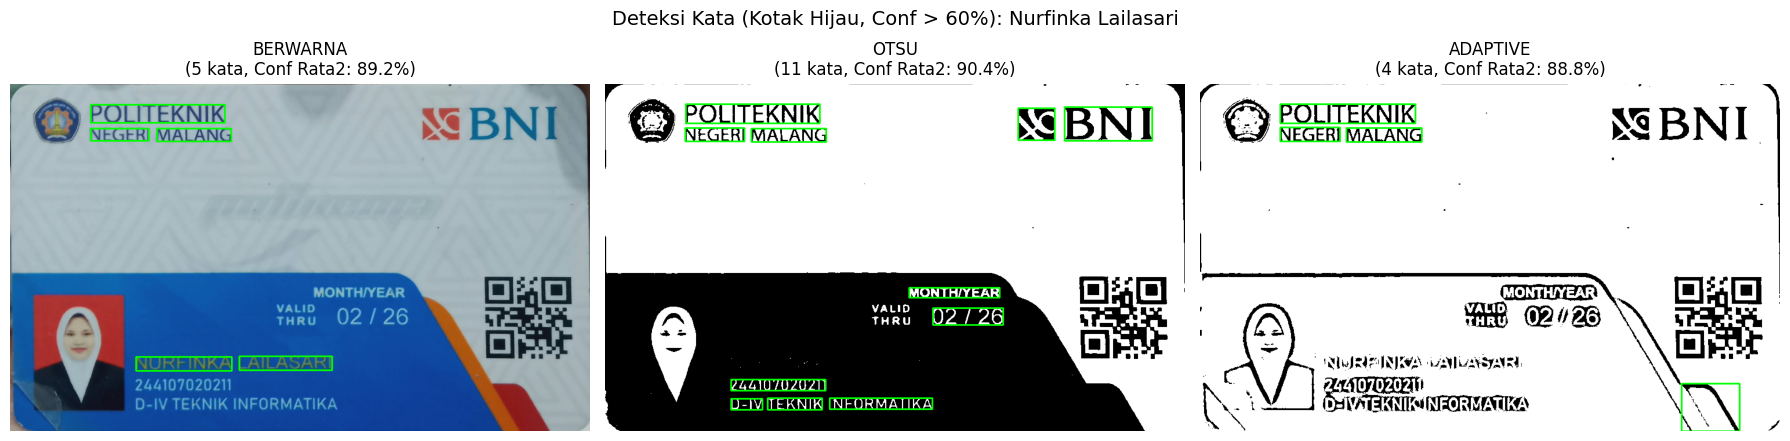

In [ ]:
rata_rata_confidence = {}

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    rata_rata_confidence[id_anggota] = {}
    gambar_annotasi = []
    judul_annotasi  = []

    for jenis_citra in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
        citra_input = citra_kelompok[id_anggota][jenis_citra]

        # Ekstraksi data bounding box dan confidence
        data_ocr = pytesseract.image_to_data(citra_input, lang=LANG_OCR, config=CONFIG_OCR,
                                             output_type=pytesseract.Output.DICT)

        # Buat kanvas berwarna untuk menggambar kotak hijau
        if citra_input.ndim == 2:
            kanvas = cv.cvtColor(citra_input, cv.COLOR_GRAY2RGB)
        else:
            kanvas = citra_input.copy()

        conf_valid = []
        n_kata = len(data_ocr['text'])

        for i in range(n_kata):
            conf_val = float(data_ocr['conf'][i])
            kata_teks = data_ocr['text'][i].strip()

            # Filter hanya kata non-kosong dengan confidence > CONF_MIN
            if conf_val > CONF_MIN and len(kata_teks) > 0:
                x = data_ocr['left'][i]
                y = data_ocr['top'][i]
                w = data_ocr['width'][i]
                h = data_ocr['height'][i]

                # Gambar persegi panjang hijau (0, 255, 0)
                cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
                conf_valid.append(conf_val)

        rata_conf = np.mean(conf_valid) if len(conf_valid) > 0 else 0.0
        rata_rata_confidence[id_anggota][jenis_citra] = rata_conf

        gambar_annotasi.append(kanvas)
        judul_annotasi.append(f"{jenis_citra}\n({len(conf_valid)} kata, Conf Rata2: {rata_conf:.1f}%)")

    # Menggantikan tampil_grid dengan subplot matplotlib standar
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    fig.suptitle(f"Deteksi Kata (Kotak Hijau, Conf > {CONF_MIN}%): {data_ag['nama_lengkap']}", fontsize=14)

    for idx in range(3):
        axes[idx].imshow(gambar_annotasi[idx])
        axes[idx].set_title(judul_annotasi[idx])
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import difflib
import re

def evaluasi_kata_acuan(teks_lengkap, kata_acuan):
    """Mengecek apakah kata_acuan ditemukan dalam teks_lengkap hasil OCR."""
    # Pecah teks menjadi token kata dan bersihkan tanda baca di pinggir kata
    token_mentah = teks_lengkap.split()
    tokens = [re.sub(r'^[^a-zA-Z0-9]+|[^a-zA-Z0-9]+$', '', t) for t in token_mentah]
    tokens = [t for t in tokens if len(t) > 0]

    kata_acuan_clean = kata_acuan.strip()

    # 1. Cek Exact Match (Case-Insensitive)
    for t in tokens:
        if t.lower() == kata_acuan_clean.lower():
            return t, True

    # 2. Cek apakah ada token yang memuat kata acuan atau sebaliknya
    for t in tokens:
        if len(kata_acuan_clean) >= 4 and (kata_acuan_clean.lower() in t.lower() or t.lower() in kata_acuan_clean.lower()):
            if abs(len(t) - len(kata_acuan_clean)) <= 2:
                return t, (t.lower() == kata_acuan_clean.lower())

    # 3. Cari kata yang paling mendekati (Similarity Match)
    matches = difflib.get_close_matches(kata_acuan_clean, tokens, n=1, cutoff=0.45)
    if len(matches) > 0:
        return matches[0], False

    return "(tidak terbaca)", False

# Evaluasi 10 kata per anggota dan susun tabelnya
semua_tabel_detail = {}
ringkasan_hasil = []

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    baris_tabel = []
    skor_cocok = {'BERWARNA': 0, 'OTSU': 0, 'ADAPTIVE': 0}

    for no, item_acuan in enumerate(data_ag['acuan'], 1):
        data_baris = {'No.': no, 'Teks Sebenarnya': item_acuan}

        for jenis in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
            teks_hasil = teks_ocr[id_anggota][jenis]
            kata_terbaca, is_cocok = evaluasi_kata_acuan(teks_hasil, item_acuan)

            simbol = "✓" if is_cocok else "✗"
            data_baris[f"OCR {jenis.title()}"] = f"{kata_terbaca} ({simbol})"
            if is_cocok:
                skor_cocok[jenis] += 1

        baris_tabel.append(data_baris)

    df_detail = pd.DataFrame(baris_tabel)
    semua_tabel_detail[id_anggota] = df_detail

    print(f"\n{'=' * 75}")
    print(f"TABEL EVALUASI 10 KATA ACUAN - {data_ag['nama_lengkap'].upper()} ({data_ag['nim']})")
    print('=' * 75)
    print(tabulate(df_detail, headers='keys', tablefmt='grid', showindex=False))

    # Simpan ringkasan untuk tabel agregat
    for jenis in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
        n_tepat = skor_cocok[jenis]
        kecocokan_pct = (n_tepat / len(data_ag['acuan'])) * 100.0
        conf_avg = rata_rata_confidence[id_anggota][jenis]

        ringkasan_hasil.append({
            'Anggota': data_ag['nama_lengkap'],
            'NIM': data_ag['nim'],
            'Citra Masukan OCR': jenis.title(),
            'Item Terbaca Tepat': f"{n_tepat} / 10",
            'Kecocokan (%)': f"{kecocokan_pct:.1f}%",
            'Rata-rata Confidence': f"{conf_avg:.1f}%"
        })


TABEL EVALUASI 10 KATA ACUAN - MUHAMMAD RAYHAN ZAMZAMI (244107020027)
+-------+-------------------+---------------------+---------------------+---------------------+
|   No. | Teks Sebenarnya   | OCR Berwarna        | OCR Otsu            | OCR Adaptive        |
+=======+===================+=====================+=====================+=====================+
|     1 | POLITEKNIK        | POLITEKNIK (✓)      | POLITEKNIK (✓)      | (tidak terbaca) (✗) |
+-------+-------------------+---------------------+---------------------+---------------------+
|     2 | NEGERI            | NEGERI (✓)          | NEGERI (✓)          | (tidak terbaca) (✗) |
+-------+-------------------+---------------------+---------------------+---------------------+
|     3 | MALANG            | MALANG (✓)          | MALANG (✓)          | (tidak terbaca) (✗) |
+-------+-------------------+---------------------+---------------------+---------------------+
|     4 | BNI               | (tidak terbaca) (✗) | (tidak terbac

In [ ]:
# Tampilkan Tabel Ringkasan per Anggota & Keseluruhan
df_ringkasan = pd.DataFrame(ringkasan_hasil)

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    print(f"\n{'=' * 70}")
    print(f"RINGKASAN OCR: {data_ag['nama_lengkap'].upper()} ({data_ag['nim']})")
    print('=' * 70)
    sub_df = df_ringkasan[df_ringkasan['NIM'] == data_ag['nim']][['Citra Masukan OCR', 'Item Terbaca Tepat', 'Kecocokan (%)', 'Rata-rata Confidence']]
    print(tabulate(sub_df, headers='keys', tablefmt='grid', showindex=False))

print(f"\n{'=' * 85}")
print("TABEL REKAPITULASI KESELURUHAN ANGGOTA KELOMPOK")
print('=' * 85)
print(tabulate(df_ringkasan, headers='keys', tablefmt='grid', showindex=False))


RINGKASAN OCR: MUHAMMAD RAYHAN ZAMZAMI (244107020027)
+---------------------+----------------------+-----------------+------------------------+
| Citra Masukan OCR   | Item Terbaca Tepat   | Kecocokan (%)   | Rata-rata Confidence   |
+=====================+======================+=================+========================+
| Berwarna            | 9 / 10               | 90.0%           | 90.6%                  |
+---------------------+----------------------+-----------------+------------------------+
| Otsu                | 6 / 10               | 60.0%           | 90.2%                  |
+---------------------+----------------------+-----------------+------------------------+
| Adaptive            | 1 / 10               | 10.0%           | 89.0%                  |
+---------------------+----------------------+-----------------+------------------------+

RINGKASAN OCR: MOHAMMAD AL HAFIS HIDAYATULLOH (254107023005)
+---------------------+----------------------+-----------------+---------

# ANALISIS

Berdasarkan tabel rekapitulasi OCR yang Anda berikan, berikut adalah analisis dari kelima pertanyaan tersebut:

1. Citra Masukan Paling Tepat:
Citra Berwarna pada percobaan Muhammad Rayhan Zamzami menghasilkan pembacaan paling tepat. Buktinya pada tabel, citra tersebut mencapai Kecocokan 90.0% dengan 9 dari 10 item terbaca dengan tepat, menjadikannya metrik tertinggi di seluruh rekapitulasi. Secara keseluruhan, citra Berwarna dan Otsu mendominasi hasil terbaik dibandingkan citra Adaptive.

2. Kesalahan Pembacaan:
Tabel yang dilampirkan hanya berisi data kuantitatif (jumlah item tepat, persentase kecocokan, dan confidence). Spesifikasi kualitatif terkait kesalahan pembacaan (seperti huruf yang tertukar, angka yang salah, atau bagian teks spesifik yang tidak terbaca) tidak dapat diidentifikasi karena tidak tercantum dalam rekapitulasi tersebut.

3. Efek Segmentasi Terhadap Ketepatan OCR:
Segmentasi (dalam hal ini menggunakan metode Otsu dan Adaptive) tidak selalu meningkatkan ketepatan OCR. Berdasarkan tabel, segmentasi justru menurunkan akurasi pada beberapa kasus:

- Pada data Muhammad Rayhan Zamzami, citra Berwarna (90.0%) jauh lebih akurat dibandingkan setelah disegmentasi dengan Otsu (60.0%) maupun Adaptive (10.0%).

- Hal serupa terjadi pada Mohammad Al Hafis Hidayatulloh, di mana citra Berwarna (50.0%) lebih unggul dari Otsu (30.0%) dan Adaptive (0.0%).

4. Pengaruh Warna/Pola Latar Belakang:
Meskipun detail visual latar belakang tidak ditampilkan, anjloknya tingkat kecocokan pada metode Adaptive (terendah 0.0%, tertinggi hanya 30.0%) secara konsisten pada semua anggota menunjukkan bahwa noise, bayangan, atau pola latar belakang pada citra gagal diisolasi dengan baik oleh algoritma Adaptive thresholding. Hal ini membuat teks menyatu dengan latar belakang atau rusak, sehingga OCR gagal membacanya.

4. Rata-rata Confidence vs Kecocokan Tertinggi:
Ya, dalam data ini nilai Rata-rata Confidence tertinggi selalu berbanding lurus dengan persentase Kecocokan tertinggi pada setiap individu:

- Muhammad Rayhan: Confidence tertinggi 90.6% (Berwarna) ➔ Kecocokan tertinggi 90.0%.

- Mohammad Al Hafis: Confidence tertinggi 91.6% (Berwarna) ➔ Kecocokan tertinggi 50.0%.

- Radit Firansah: Confidence tertinggi 90.1% (Otsu) ➔ Kecocokan tertinggi 80.0%.

- Nurfinka Lailasari: Confidence tertinggi 90.4% (Otsu) ➔ Kecocokan tertinggi 80.0%.

In [ ]:
!jupyter nbconvert --to html "/content/drive/MyDrive/PCVK-2026/week7_19.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/PCVK-2026/week7_19.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 17 image(s).
[NbConvertApp] Writing 8086727 bytes to /content/drive/MyDrive/PCVK-2026/week7_19.html
